# cim_replica_schematic.py

*Generated from `cim_replica_schematic.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
cim_replica_schematic.py - how the CIM replicas branch from the main run.

Draws the main CIM trajectory (cycles 0 -> end), the checkpoints written every
500 cycles, and N independent 100-cycle replicas fanning out of the 0, 500 and
1000-cycle checkpoints, each giving one yield sample; mean +- 95% CI per branch.

Usage:  python cim_replica_schematic.py [--nrep 10] [--ncyc 100] [--out cim_replica_branches.png]
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'cim_replica_schematic.py'
NB_OUT = "nb_figs"
os.makedirs("nb_figs", exist_ok=True)
ARGS = ["--nrep", "10", "--ncyc", "100", "--out", os.path.join(NB_OUT, "cim_replica_branches.png")]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

In [2]:
import argparse

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

In [3]:
MAIN_END = 1550          # cycles of the main run drawn
BRANCHES = (0, 500, 1000)
PER_CYCLE = 2.80e16      # He m^-2 per cycle (WC basal impact area)
C_MAIN, C_REP, C_CI, C_CK = "#4b4b4b", "#e2711d", "#7d0a12", "#2b7bba"


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--nrep", type=int, default=10)
    ap.add_argument("--ncyc", type=int, default=100)
    ap.add_argument("--out", default="cim_replica_branches.png")
    a = ap.parse_args()
    rng = np.random.default_rng(3)

    fig, ax = plt.subplots(figsize=(9.0, 4.6))
    # main run
    ax.annotate("", xy=(MAIN_END + 60, 0), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", lw=6, color="#bfbfbf", shrinkA=0, shrinkB=0))
    ax.text(MAIN_END + 70, 0, "main CIM run\n(one trajectory)", va="center", fontsize=10, color=C_MAIN)
    for ck in range(0, MAIN_END + 1, 500):
        used = ck in BRANCHES
        ax.plot(ck, 0, "D", ms=11, color=C_CK if used else "#bfbfbf", mec="k", mew=0.6, zorder=5)
        ax.text(ck, -0.17, "he_cycle_%d.restart" % ck if ck else "wche0.restart", ha="center", va="top",
                fontsize=8.5, color=C_CK if used else "#888888")
    # replicas
    for b in BRANCHES:
        ys = np.linspace(0.18, 1.0, a.nrep)
        for k, y in enumerate(ys):
            x1 = b + a.ncyc * 2.6            # stretched so the fan is readable
            xs = np.linspace(b, x1, 30)
            yy = y * np.sin(np.linspace(0, np.pi / 2, 30))
            taper = (xs - b) / (x1 - b)
            ax.plot(xs, yy + 0.008 * rng.standard_normal(30).cumsum() * taper, color=C_REP, lw=1.1, alpha=0.85)
        ax.text(b + a.ncyc * 2.6 + 12, 1.02, "rep 1…%d" % a.nrep, fontsize=8.5, color=C_REP, va="bottom")
        # per-branch yield estimate
        xm = b + a.ncyc * 2.6 + 55
        ax.errorbar(xm, 0.58, yerr=0.2, fmt="o", color=C_CI, capsize=5, ms=6, lw=1.6)
        ax.text(xm + 18, 0.58, r"$\bar Y \pm t\,s/\sqrt{N}$", fontsize=10, color=C_CI, va="center")
    ax.text(30, 1.32, "each replica: same restart, seed = 123 + 237 i + 100003·rep  →  %d cycles  →  "
            r"$Y_r$ = atoms removed / %d" % (a.ncyc, a.ncyc), fontsize=10, color="#333333")
    # fluence axis
    ax.set_xlim(-60, MAIN_END + 260)
    ax.set_ylim(-0.42, 1.45)
    ax.set_yticks([])
    for sp in ("left", "right", "top"):
        ax.spines[sp].set_visible(False)
    ax.set_xticks(BRANCHES + (1500,))
    ax.set_xlabel("cycle of the main run  (replica fans drawn %.1f× longer than 100 cycles for clarity)" % 2.6,
                  fontsize=9.5)
    sec = ax.secondary_xaxis("top", functions=(lambda c: c * PER_CYCLE / 1e19, lambda f: f * 1e19 / PER_CYCLE))
    sec.set_xlabel(r"fluence ($10^{19}$ He m$^{-2}$, WC basal)", fontsize=9.5)
    sec.set_xticks([0, 1.4, 2.8, 4.2])
    for s_ in ("left", "right"):
        sec.spines[s_].set_visible(False)
    fig.tight_layout()
    fig.savefig(a.out, dpi=200)
    print("wrote", a.out)

In [4]:
if __name__ == "__main__":
    main()

wrote nb_figs/cim_replica_branches.png


## Outputs

In [5]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


cim_replica_branches.png


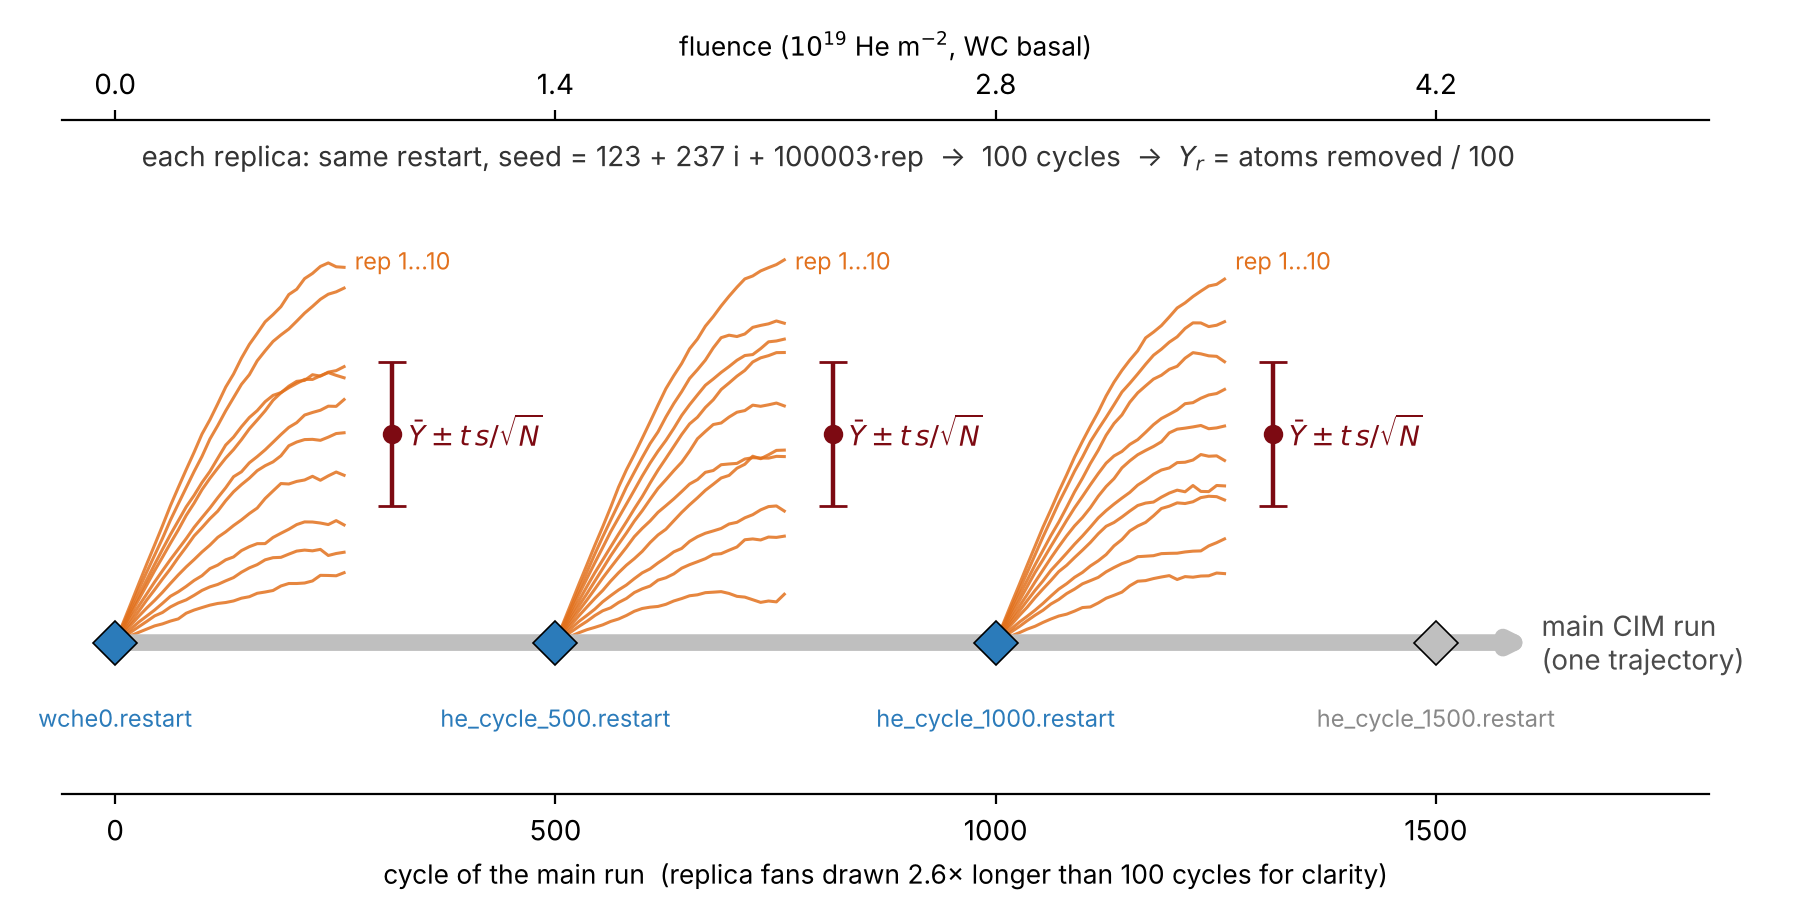

In [6]:
show(NB_OUT, ['cim_replica_branches.png'])